# Notebook 02 - Q5: Phân tích Chuyên sâu Câu hỏi Q5 (Dịch tễ đàn & Tỷ lệ ảnh hưởng ở đàn)
**Đề tài:** Phân tích Sự cố Bất lợi Thuốc Thú y (OpenFDA Animal & Veterinary Adverse Events) giai đoạn 2025 và Đối chiếu Xu hướng 2026 (Q1)

**Môn học:** CSC17104 – Lập trình cho Khoa học Dữ liệu  
**Nhóm thực hiện:** Global Ban  
**Thành viên phụ trách:** Trần Ngô Uyên Nhi  
**Phản biện chéo (Reviewer):** Đinh Công Khang  
**Liên kết Master Hub:** [Notebook 02: Master Hub (Mục 3.3 Question Formulation & D1–D6)](02_analysis.ipynb)


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.preprocessing import log_row_count_change, load_clean_tables
from src.visualization import set_project_plot_style
set_project_plot_style()
np.random.seed(42)
print("Libraries loaded. PROJECT_ROOT:", PROJECT_ROOT)

Libraries loaded. PROJECT_ROOT: D:\HCMUS_Y3\ProgrammingForDS\Prg4DS-G3


In [2]:
# Tải dữ liệu đã được tiền xử lý, chuẩn hóa từ data/processed/clean/
tables = load_clean_tables(PROJECT_ROOT / 'data' / 'processed' / 'clean')
reports_raw = tables['reports'].copy()

print(f'[Data Loaded] reports_raw: {reports_raw.shape}')
print(f'  treated non-null: {reports_raw.number_of_animals_treated.notna().sum():,}')
print(f'  affected non-null: {reports_raw.number_of_animals_affected.notna().sum():,}')
print(f'  route_primary unique: {reports_raw.route_primary.nunique()}')


[Data Loaded] reports_raw: (93812, 53)
  treated non-null: 84,093
  affected non-null: 84,093
  route_primary unique: 36


---
## Câu hỏi Q5: Các yếu tố liên quan đến Tỷ lệ Động vật Bị ảnh hưởng ở Đàn (Herd Attack Rate)

### Phát biểu câu hỏi và Động lực
- **Phát biểu câu hỏi:**  
  > **"Những yếu tố nào có liên quan đến tỷ lệ động vật bị ảnh hưởng trong tổng số động vật được điều trị ở mỗi đàn?"**
- **Biến mục tiêu:**  
  $$\text{attack\_rate} = \frac{\text{number\_of\_animals\_affected}}{\text{number\_of\_animals\_treated}} \quad (\text{xét đàn có } \text{treated} > 0)$$
- **Người quan tâm & Quyết định hỗ trợ (Target Users & Decisions):**
  - **Bác sĩ thú y trang trại & Chủ trang trại chăn nuôi:** Cần biết yếu tố nào (loài gia súc: Bò, Heo, Gà; đường dùng thuốc: tiêm, pha nước uống, trộn thức ăn; quy mô đàn) làm trầm trọng hóa mức độ lan rộng của sự cố để xây dựng phương án phòng ngừa.
  - **Cơ quan quản lý an toàn dịch tễ:** Giám sát rủi ro ngộ độc hoặc phản ứng phụ diện rộng trong chăn nuôi công nghiệp.
- **Tiêu chí độ sâu áp dụng (Mục 3.3):**
  - `D1` (Combining data): Nối thông tin báo cáo đàn `reports` với bảng thông tin thuốc `drugs` (đường dùng, nhóm thuốc).
  - `D3` (Derived variables): Tính toán biến tỷ lệ $\text{attack\_rate} \in [0, 1]$ và phân nhóm quy mô đàn (`herd_size_group`).
  - `D4` (Controlling for a confounder): Kiểm soát loài đàn (Bò vs Loài khác) và phân loại quy mô đàn khi đánh giá tác động của đường dùng thuốc.
  - `D5` (Quantifying uncertainty): Kiểm định Kruskal-Wallis / Mann-Whitney U, Bootstrap CI 95% cho trung vị tỷ lệ ảnh hưởng.
  - `D6` (Robustness check): So sánh kết luận khi loại trừ một ca ngoại lai có $\text{attack\_rate} > 1$ hoặc chặn giá trị ở 1.0.


### 1. Tiền xử lý cho Q5

Quy trình chuẩn bị dữ liệu cho Q5 gồm 4 bước lọc, theo dõi biến động số dòng bằng `log_row_count_change()`:

1. **Bước 1.1 — Lọc gia súc, gia cầm:** Giữ lại báo cáo thuộc các loài vật nuôi trang trại (`Cattle`, `Pig`, `Chicken`, `Goat`, `Sheep`, `Turkey`), loại chó, mèo, ngựa và thú cưng khác.
2. **Bước 1.2 — Lọc báo cáo đàn hợp lệ:** Chỉ giữ báo cáo có `number_of_animals_treated > 0` và `number_of_animals_affected` không bị thiếu.
3. **Bước 1.3 — Tính biến dẫn xuất (D3):**
   - `attack_rate = number_of_animals_affected / number_of_animals_treated`.
   - `herd_size_group`: phân nhóm quy mô đàn theo phân vị Q33/Q67.
4. **Bước 1.4 — Baseline và tập D6:** Giữ ca ngoại lai `attack_rate > 1` trong baseline; tạo tập D6-R1 (loại ngoại lai) và D6-R2 (chặn giá trị ở 1.0).

In [3]:
# ===== 1. TIỀN XỬ LÝ DỮ LIỆU CHO Q5 (kèm log_row_count_change) =====

LIVESTOCK_SPECIES = ['Cattle', 'Pig', 'Chicken', 'Goat', 'Sheep', 'Turkey']

# --- Bước 1.1: Lọc gia súc, gia cầm ---
n0 = len(reports_raw)
q5_lv = reports_raw[reports_raw['species'].isin(LIVESTOCK_SPECIES)].copy()
log_row_count_change('1.1 Lọc gia súc, gia cầm', n0, len(q5_lv),
                     'Giữ lại 6 loài gia súc, gia cầm (Cattle, Pig, Chicken, Goat, Sheep, Turkey)')

# --- Bước 1.2: Lọc báo cáo đàn hợp lệ ---
n1 = len(q5_lv)
q5_herd = q5_lv[
    q5_lv['number_of_animals_treated'].notna() &
    (q5_lv['number_of_animals_treated'].astype(float) > 0) &
    q5_lv['number_of_animals_affected'].notna()
].copy()
log_row_count_change('1.2 Lọc báo cáo đàn hợp lệ (treated > 0, affected không thiếu)', n1, len(q5_herd),
                     'Loại ca thiếu thông tin số lượng điều trị hoặc bị ảnh hưởng')

# --- Bước 1.3: Tính biến dẫn xuất (D3) ---
q5_herd = q5_herd.assign(
    treated_n=q5_herd['number_of_animals_treated'].astype(float),
    affected_n=q5_herd['number_of_animals_affected'].astype(float),
)
q5_herd['attack_rate'] = q5_herd['affected_n'] / q5_herd['treated_n']

# Phân nhóm quy mô đàn theo phân vị Q33/Q67
q33 = q5_herd['treated_n'].quantile(0.33)
q67 = q5_herd['treated_n'].quantile(0.67)
print(f'Phân vị quy mô đàn: Q33 = {q33:.0f}, Q67 = {q67:.0f}')

SIZE_LABELS = {
    'Nhỏ (< Q33)': lambda x: x < q33,
    'Vừa (Q33-Q67)': lambda x: (x >= q33) & (x <= q67),
    'Lớn (> Q67)': lambda x: x > q67,
}
q5_herd['herd_size_group'] = 'Vừa (Q33-Q67)'
q5_herd.loc[q5_herd['treated_n'] < q33, 'herd_size_group'] = 'Nhỏ (< Q33)'
q5_herd.loc[q5_herd['treated_n'] > q67, 'herd_size_group'] = 'Lớn (> Q67)'

# Chuẩn hóa route_grp
MAIN_ROUTES = ['Subcutaneous', 'Oral', 'Intramuscular', 'Topical', 'Intramammary']
q5_herd['route_grp'] = q5_herd['route_primary'].apply(
    lambda r: r if r in MAIN_ROUTES else ('Unknown' if r == 'Unknown' else 'Other/Parenteral')
)

# --- Bước 1.4: Baseline D6 ---
outlier_n = int((q5_herd['attack_rate'] > 1).sum())
print(f'\nBaseline: {len(q5_herd)} báo cáo đàn gia súc, gia cầm hợp lệ')
print(f'Ca ngoại lai (attack_rate > 1): {outlier_n}')

q5_excl = q5_herd[q5_herd['attack_rate'] <= 1.0].copy()   # D6-R1
q5_clip = q5_herd.copy()                                   # D6-R2
q5_clip['attack_rate'] = q5_clip['attack_rate'].clip(upper=1.0)
print(f'D6-R1 (loại ca ngoại lai): {len(q5_excl)} báo cáo')
print(f'D6-R2 (chặn ở 1.0): {len(q5_clip)} báo cáo')
print()

print('=== Tóm tắt phân phối attack_rate (Baseline) ===')
print(q5_herd['attack_rate'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(4))
print()
print('=== Phân phối theo loài ===')
display(
    q5_herd.groupby('species', observed=True)['attack_rate']
    .agg(['count', 'median', 'mean',
          lambda x: round(x.quantile(0.25), 4),
          lambda x: round(x.quantile(0.75), 4)])
    .rename(columns={'count': 'n', 'median': 'Trung vị', 'mean': 'Trung bình',
                     '<lambda_0>': 'Q25', '<lambda_1>': 'Q75'})
    .round(4)
)
print()
print('=== Phân phối theo đường dùng thuốc ===')
display(
    q5_herd.groupby('route_grp', observed=True)['attack_rate']
    .agg(['count', 'median', 'mean',
          lambda x: round(x.quantile(0.25), 4),
          lambda x: round(x.quantile(0.75), 4)])
    .rename(columns={'count': 'n', 'median': 'Trung vị', 'mean': 'Trung bình',
                     '<lambda_0>': 'Q25', '<lambda_1>': 'Q75'})
    .sort_values('n', ascending=False).round(4)
)

[1.1 Lọc gia súc, gia cầm] Rows: 93,812 -> 964 (Change: -92,848 | -98.97%) | Reason: Giữ lại 6 loài gia súc, gia cầm (Cattle, Pig, Chicken, Goat, Sheep, Turkey)
[1.2 Lọc báo cáo đàn hợp lệ (treated > 0, affected không thiếu)] Rows: 964 -> 964 (Change: +0 | +0.00%) | Reason: Loại ca thiếu thông tin số lượng điều trị hoặc bị ảnh hưởng
Phân vị quy mô đàn: Q33 = 20, Q67 = 144

Baseline: 964 báo cáo đàn gia súc, gia cầm hợp lệ
Ca ngoại lai (attack_rate > 1): 1
D6-R1 (loại ca ngoại lai): 963 báo cáo
D6-R2 (chặn ở 1.0): 964 báo cáo

=== Tóm tắt phân phối attack_rate (Baseline) ===
count    964.0000
mean       0.5203
std        0.4110
min        0.0000
10%        0.0260
25%        0.1000
50%        0.4325
75%        1.0000
90%        1.0000
max        1.2857
Name: attack_rate, dtype: float64

=== Phân phối theo loài ===


,n,Trung vị,Trung bình,Q25,Q75
species,,,,,
Cattle,801,0.4000,0.5070,0.1000,1.0
Chicken,38,0.2083,0.4283,0.0191,1.0
Goat,34,1.0000,0.7208,0.3537,1.0
Pig,67,1.0000,0.5899,0.0976,1.0
Sheep,15,0.8333,0.6680,0.5000,1.0
Turkey,9,0.6667,0.5627,0.1000,1.0



=== Phân phối theo đường dùng thuốc ===


,n,Trung vị,Trung bình,Q25,Q75
route_grp,,,,,
Subcutaneous,309,0.3333,0.4492,0.1111,0.8579
Oral,264,0.1647,0.4030,0.0310,1.0000
Unknown,168,1.0000,0.6589,0.2294,1.0000
Other/Parenteral,66,0.4746,0.5312,0.1202,1.0000
Intramuscular,59,1.0000,0.7426,0.4408,1.0000
Topical,55,1.0000,0.7583,0.5992,1.0000
Intramammary,43,0.5000,0.5832,0.2167,1.0000


### 2. Phương pháp phân tích

Vì `attack_rate` không phân phối chuẩn (tập trung tại 0 và 1), nhóm sử dụng phương pháp **phi tham số** kết hợp **bootstrap**:

- **D1 (Kết hợp dữ liệu):** `route_primary` trong `reports.csv` đã được tổng hợp từ bảng `drugs` trong quy trình tiền xử lý.
- **D3 (Biến dẫn xuất):** `attack_rate`, `herd_size_group`, `route_grp`.
- **D4 (Kiểm soát yếu tố gây nhiễu):** Phân tầng theo loài (`Cattle` và `Non-Cattle`) khi so sánh đường dùng thuốc.
- **D5 (Định lượng độ bất định):** Kiểm định Kruskal–Wallis, hậu kiểm Mann–Whitney U + Bonferroni, bootstrap CI 95% cho trung vị.
- **D6 (Kiểm tra độ vững):** So sánh baseline, R1 (loại ca `attack_rate > 1`) và R2 (chặn `attack_rate` ở 1.0).

In [4]:
# ===== 2. PHÂN TÍCH THỐNG KÊ CHO Q5 =====

B = 1000

def bootstrap_median_ci(arr, B=1000, alpha=0.05, seed=42):
    """Bootstrap CI 95% cho trung vị."""
    rng = np.random.default_rng(seed)
    arr = np.asarray(arr, dtype=float)
    arr = arr[~np.isnan(arr)]
    if len(arr) < 2:
        return np.median(arr) if len(arr) == 1 else np.nan, np.nan, np.nan
    boot = rng.choice(arr, size=(B, len(arr)), replace=True)
    medians = np.median(boot, axis=1)
    return float(np.median(arr)), float(np.quantile(medians, alpha/2)), float(np.quantile(medians, 1-alpha/2))

# --- A. Kruskal–Wallis theo route_grp (loại Unknown) ---
ROUTE_ORDER = ['Subcutaneous', 'Oral', 'Intramuscular', 'Topical', 'Intramammary', 'Other/Parenteral', 'Unknown']
route_groups_known = [g for g in ROUTE_ORDER if g != 'Unknown' and g in q5_herd['route_grp'].unique()]
route_arrs = [q5_herd[q5_herd['route_grp'] == g]['attack_rate'].dropna().values for g in route_groups_known]
kw_stat_route, kw_p_route = stats.kruskal(*route_arrs)
print(f'=== Kruskal–Wallis -- attack_rate theo đường dùng thuốc ===')
print(f'H = {kw_stat_route:.4f}, p = {kw_p_route:.4e} ({"Khác biệt có ý nghĩa" if kw_p_route < 0.05 else "Không có ý nghĩa"})')
print()

# Bootstrap CI theo route_grp
route_rows = []
for grp in [g for g in ROUTE_ORDER if g in q5_herd['route_grp'].unique()]:
    arr = q5_herd[q5_herd['route_grp'] == grp]['attack_rate'].dropna().values
    med, lo, hi = bootstrap_median_ci(arr, B=B)
    route_rows.append({'Nhóm đường dùng': grp, 'n': len(arr),
                       'Trung vị': med, 'CI 95% thấp': lo, 'CI 95% cao': hi})
df_route_ci = pd.DataFrame(route_rows)
print('=== Bootstrap CI 95% trung vị attack_rate theo đường dùng thuốc ===')
display(df_route_ci.round(4))
print()

# Hậu kiểm Mann–Whitney U + Bonferroni
route_large = [g for g in route_groups_known
               if len(q5_herd[q5_herd['route_grp'] == g]) >= 10]
pairs = [(a, b) for i, a in enumerate(route_large) for b in route_large[i+1:]]
mw_rows = []
for g1, g2 in pairs:
    a1 = q5_herd[q5_herd['route_grp'] == g1]['attack_rate'].dropna().values
    a2 = q5_herd[q5_herd['route_grp'] == g2]['attack_rate'].dropna().values
    u, p_raw = stats.mannwhitneyu(a1, a2, alternative='two-sided')
    p_bonf = min(p_raw * len(pairs), 1.0)
    r_rb = (2.0 * u) / (len(a1) * len(a2)) - 1.0
    mw_rows.append({'Cặp so sánh': f'{g1} vs {g2}',
                    'U-stat': int(u), 'p thô': p_raw, 'p Bonferroni': p_bonf,
                    'Rank-biserial r': r_rb})
df_mw = pd.DataFrame(mw_rows)
print(f'=== Hậu kiểm Mann–Whitney U (Bonferroni, {len(pairs)} cặp) ===')
display(df_mw.style.format({'p thô': '{:.4e}', 'p Bonferroni': '{:.4e}', 'Rank-biserial r': '{:+.4f}'}))
print()

# --- B. Kruskal–Wallis theo herd_size_group ---
SIZE_GRP_ORDER = ['Nhỏ (< Q33)', 'Vừa (Q33-Q67)', 'Lớn (> Q67)']
size_arrs = [q5_herd[q5_herd['herd_size_group'] == g]['attack_rate'].dropna().values
             for g in SIZE_GRP_ORDER]
kw_stat_size, kw_p_size = stats.kruskal(*size_arrs)
print(f'=== Kruskal–Wallis -- attack_rate theo quy mô đàn ===')
print(f'H = {kw_stat_size:.4f}, p = {kw_p_size:.4e}')

size_rows = []
for grp in SIZE_GRP_ORDER:
    arr = q5_herd[q5_herd['herd_size_group'] == grp]['attack_rate'].dropna().values
    med, lo, hi = bootstrap_median_ci(arr, B=B)
    size_rows.append({'Nhóm quy mô': grp, 'n': len(arr),
                      'Trung vị': med, 'CI 95% thấp': lo, 'CI 95% cao': hi})
df_size_ci = pd.DataFrame(size_rows)
print('=== Bootstrap CI 95% trung vị attack_rate theo quy mô đàn ===')
display(df_size_ci.round(4))
print()

# --- C. D4 phân tầng: Cattle và Non-Cattle theo đường dùng ---
q5_herd['species_grp'] = q5_herd['species'].apply(lambda s: 'Cattle' if s == 'Cattle' else 'Non-Cattle')
print('=== D4 -- Phân tầng: trung vị attack_rate theo route_grp và loài ===')
d4_rows = []
for sp in ['Cattle', 'Non-Cattle']:
    for rt in [g for g in ROUTE_ORDER if g in q5_herd['route_grp'].unique()]:
        sub = q5_herd[(q5_herd['species_grp'] == sp) & (q5_herd['route_grp'] == rt)]
        if len(sub) >= 5:
            d4_rows.append({'Loài': sp, 'Đường dùng': rt,
                            'n': len(sub), 'Trung vị attack_rate': round(sub['attack_rate'].median(), 4)})
display(pd.DataFrame(d4_rows))

=== Kruskal–Wallis -- attack_rate theo đường dùng thuốc ===
H = 68.7720, p = 1.8454e-13 (Khác biệt có ý nghĩa)



=== Bootstrap CI 95% trung vị attack_rate theo đường dùng thuốc ===


,Nhóm đường dùng,n,Trung vị,CI 95% thấp,CI 95% cao
0,Subcutaneous,309,0.3333,0.3000,0.40
1,Oral,264,0.1647,0.1011,0.25
2,Intramuscular,59,1.0000,0.9231,1.00
3,Topical,55,1.0000,1.0000,1.00
4,Intramammary,43,0.5000,0.3684,1.00
5,Other/Parenteral,66,0.4746,0.2632,0.85
6,Unknown,168,1.0000,0.6314,1.00


=== Hậu kiểm Mann–Whitney U (Bonferroni, 15 cặp) ===


,Cặp so sánh,U-stat,p thô,p Bonferroni,Rank-biserial r
0,Subcutaneous vs Oral,47516,5.9023e-04,8.8534e-03,+0.1650
1,Subcutaneous vs Intramuscular,5515,1.1293e-06,1.6940e-05,-0.3950
2,Subcutaneous vs Topical,4956,5.9227e-07,8.8841e-06,-0.4168
3,Subcutaneous vs Intramammary,5355,3.7767e-02,5.6650e-01,-0.1939
4,Subcutaneous vs Other/Parenteral,9221,2.1811e-01,1.0000e+00,-0.0957
5,Oral vs Intramuscular,4295,4.1624e-08,6.2436e-07,-0.4485
6,Oral vs Topical,3878,2.9215e-08,4.3822e-07,-0.4658
7,Oral vs Intramammary,3987,1.5361e-03,2.3042e-02,-0.2975
8,Oral vs Other/Parenteral,6700,3.2763e-03,4.9145e-02,-0.2309
9,Intramuscular vs Topical,1519,5.1294e-01,1.0000e+00,-0.0638



=== Kruskal–Wallis -- attack_rate theo quy mô đàn ===
H = 286.7002, p = 5.5443e-63
=== Bootstrap CI 95% trung vị attack_rate theo quy mô đàn ===


,Nhóm quy mô,n,Trung vị,CI 95% thấp,CI 95% cao
0,Nhỏ (< Q33),312,1.0000,1.00,1.0000
1,Vừa (Q33-Q67),334,0.2977,0.25,0.3383
2,Lớn (> Q67),318,0.1348,0.10,0.2000



=== D4 -- Phân tầng: trung vị attack_rate theo route_grp và loài ===


,Loài,Đường dùng,n,Trung vị attack_rate
0,Cattle,Subcutaneous,302,0.3333
1,Cattle,Oral,179,0.1364
2,Cattle,Intramuscular,46,1.0000
3,Cattle,Topical,55,1.0000
4,Cattle,Intramammary,41,0.6000
5,Cattle,Other/Parenteral,53,0.3521
6,Cattle,Unknown,125,0.6429
7,Non-Cattle,Subcutaneous,7,0.5000
8,Non-Cattle,Oral,85,0.2000
9,Non-Cattle,Intramuscular,13,0.9091


### 3. Kết quả và trực quan hóa

Ba biểu đồ dưới đây minh họa các phát hiện chính của câu hỏi Q5:
- **Hình 1:** Phân phối `attack_rate` theo đường dùng thuốc, kèm CI bootstrap 95%.
- **Hình 2:** Phân phối `attack_rate` theo loài gia súc, gia cầm, kèm số lượng báo cáo.
- **Hình 3:** So sánh trung vị `attack_rate` theo đường dùng trong ba kịch bản D6: baseline, R1 (loại ngoại lai), R2 (chặn ở 1.0).

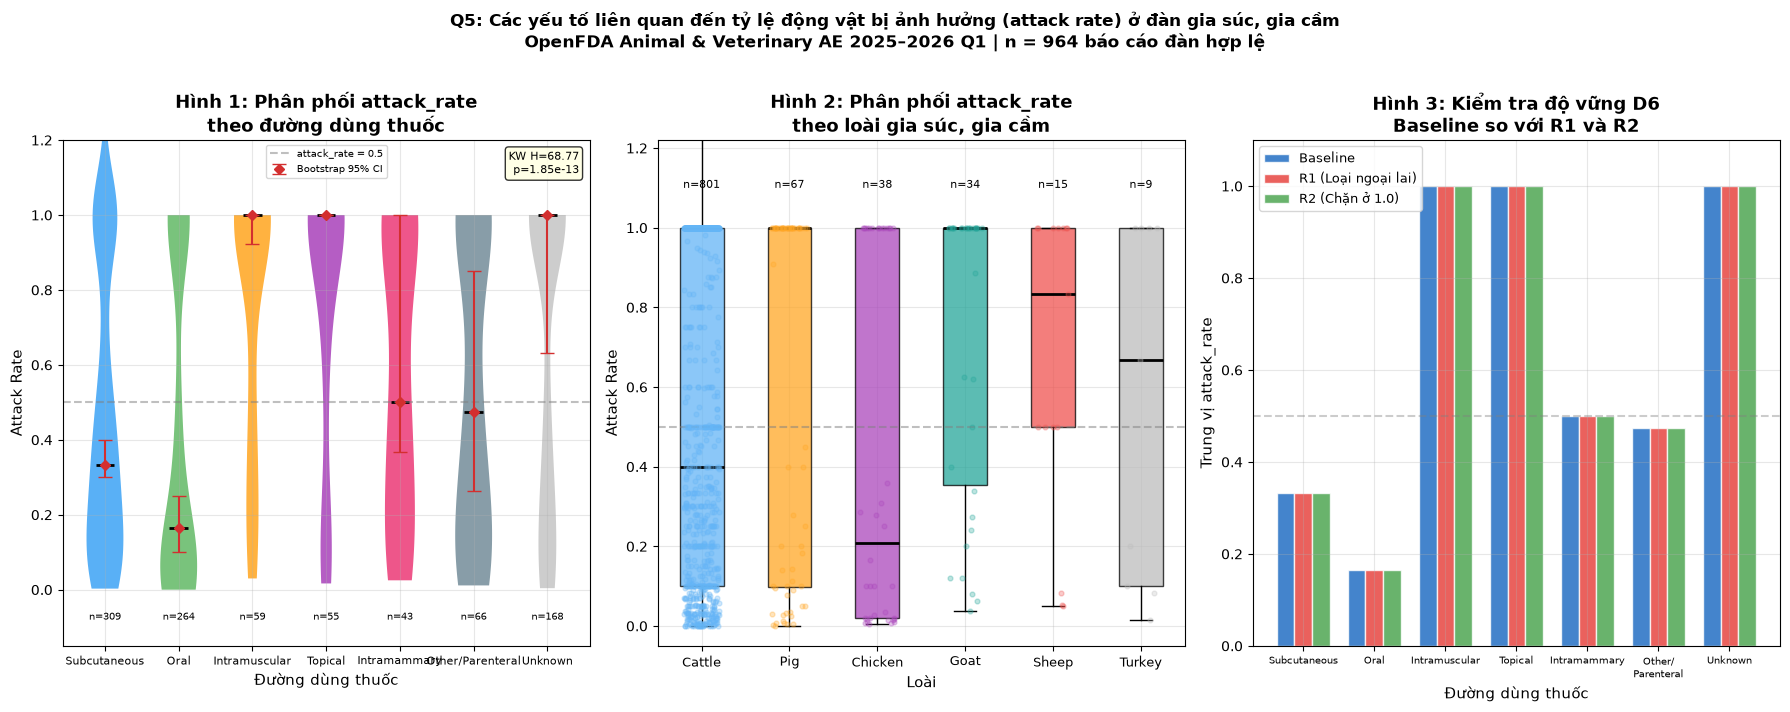

In [5]:
# ===== 3. TRỰC QUAN HÓA KẾT QUẢ Q5 =====

ROUTE_COLORS = {
    'Subcutaneous': '#2196F3', 'Oral': '#4CAF50', 'Intramuscular': '#FF9800',
    'Topical': '#9C27B0', 'Intramammary': '#E91E63',
    'Other/Parenteral': '#607D8B', 'Unknown': '#BDBDBD'
}
SPECIES_ORDER = [s for s in ['Cattle', 'Pig', 'Chicken', 'Goat', 'Sheep', 'Turkey']
                 if s in q5_herd['species'].unique()]

route_order_present = [r for r in ROUTE_ORDER if r in q5_herd['route_grp'].unique()]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
n_herd = len(q5_herd)
fig.suptitle(
    'Q5: Các yếu tố liên quan đến tỷ lệ động vật bị ảnh hưởng (attack rate) ở đàn gia súc, gia cầm\n'
    f'OpenFDA Animal & Veterinary AE 2025–2026 Q1 | n = {n_herd:,} báo cáo đàn hợp lệ',
    fontsize=12, fontweight='bold', y=1.01
)

# --- Hình 1: Biểu đồ violin attack_rate theo route_grp ---
ax1 = axes[0]
data_violin = [q5_herd[q5_herd['route_grp'] == r]['attack_rate'].dropna().values
               for r in route_order_present]
parts = ax1.violinplot(data_violin, positions=range(len(route_order_present)),
                       showmedians=True, showextrema=False)
for i, (pc, rt) in enumerate(zip(parts['bodies'], route_order_present)):
    pc.set_facecolor(ROUTE_COLORS.get(rt, '#90A4AE'))
    pc.set_alpha(0.75)
parts['cmedians'].set_color('black')
parts['cmedians'].set_linewidth(2)

for i, rt in enumerate(route_order_present):
    arr = q5_herd[q5_herd['route_grp'] == rt]['attack_rate'].dropna().values
    if len(arr) >= 2:
        med, lo, hi = bootstrap_median_ci(arr, B=B)
        ax1.errorbar(i, med, yerr=[[med - lo], [hi - med]],
                     fmt='D', color='#D32F2F', capsize=5, ms=5, zorder=5,
                     label='Bootstrap 95% CI' if i == 0 else '')
    n_rt = len(arr)
    ax1.text(i, -0.08, f'n={n_rt}', ha='center', fontsize=7.5)

ax1.set_xticks(range(len(route_order_present)))
ax1.set_xticklabels([r.replace(' ', '\n') for r in route_order_present], fontsize=8)
ax1.set_ylabel('Attack Rate')
ax1.set_xlabel('Đường dùng thuốc')
ax1.set_title('Hình 1: Phân phối attack_rate\ntheo đường dùng thuốc', fontweight='bold')
ax1.axhline(0.5, color='grey', linestyle='--', alpha=0.5, label='attack_rate = 0.5')
ax1.set_ylim(-0.15, 1.2)
ax1.legend(fontsize=7)
ax1.text(0.98, 0.98, f'KW H={kw_stat_route:.2f}\np={kw_p_route:.2e}',
         transform=ax1.transAxes, ha='right', va='top', fontsize=8,
         bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

# --- Hình 2: Boxplot attack_rate theo loài ---
ax2 = axes[1]
colors2 = ['#64B5F6', '#FFA726', '#AB47BC', '#26A69A', '#EF5350', '#BDBDBD']
data_box = [q5_herd[q5_herd['species'] == sp]['attack_rate'].dropna().values
            for sp in SPECIES_ORDER]
bp = ax2.boxplot(data_box, tick_labels=SPECIES_ORDER,
                 patch_artist=True, medianprops=dict(color='black', linewidth=2))
for patch, c in zip(bp['boxes'], colors2):
    patch.set_facecolor(c)
    patch.set_alpha(0.75)

for i, sp in enumerate(SPECIES_ORDER):
    vals = q5_herd[q5_herd['species'] == sp]['attack_rate'].dropna().values
    jitter = np.random.default_rng(42+i).uniform(-0.2, 0.2, len(vals))
    ax2.scatter(np.ones(len(vals)) * (i+1) + jitter, vals,
                alpha=0.3, s=12, color=colors2[i], zorder=3)
    ax2.text(i+1, 1.1, f'n={len(vals)}', ha='center', fontsize=8)

ax2.set_ylabel('Attack Rate')
ax2.set_xlabel('Loài')
ax2.set_title('Hình 2: Phân phối attack_rate\ntheo loài gia súc, gia cầm', fontweight='bold')
ax2.set_ylim(-0.05, 1.22)
ax2.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
ax2.tick_params(axis='x', labelsize=9)

# --- Hình 3: Kiểm tra độ vững D6 ---
ax3 = axes[2]
scenarios = {
    'Baseline': q5_herd,
    'R1 (Loại ngoại lai)': q5_excl,
    'R2 (Chặn ở 1.0)': q5_clip,
}
x = np.arange(len(route_order_present))
width = 0.25
scen_colors = ['#1565C0', '#E53935', '#43A047']
for i, (scen_name, scen_df) in enumerate(scenarios.items()):
    medians = []
    for rt in route_order_present:
        sub = scen_df[scen_df['route_grp'] == rt]['attack_rate']
        medians.append(float(sub.median()) if len(sub) > 0 else 0.0)
    ax3.bar(x + i*width, medians, width, label=scen_name,
            color=scen_colors[i], alpha=0.8, edgecolor='white')

ax3.set_xticks(x + width)
ax3.set_xticklabels([r.replace(' ', '\n').replace('/', '/\n')
                     for r in route_order_present], fontsize=7.5)
ax3.set_ylabel('Trung vị attack_rate')
ax3.set_xlabel('Đường dùng thuốc')
ax3.set_title('Hình 3: Kiểm tra độ vững D6\nBaseline so với R1 và R2', fontweight='bold')
ax3.legend(fontsize=9)
ax3.set_ylim(0, 1.1)
ax3.axhline(0.5, color='grey', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


### 4. Trả lời câu hỏi và thảo luận

Trên 964 báo cáo đàn gia súc, gia cầm hợp lệ, `attack_rate` có trung vị 0.4325 và trung bình 0.5203. Có một ca ngoại lai duy nhất với `attack_rate = 1.2857`; loại bỏ (R1) hoặc chặn giá trị này (R2) không làm thay đổi các trung vị theo đường dùng.

- **Đường dùng thuốc:** Intramuscular và Topical có trung vị cao nhất (1.0000; CI 95% lần lượt 0.9231–1.0000 và 1.0000–1.0000), tiếp theo là Intramammary (0.5000). Oral có trung vị thấp nhất (0.1647; CI 95% 0.1011–0.2500), còn Subcutaneous là 0.3333 (CI 95% 0.3000–0.4000). Kruskal–Wallis trên các nhóm đường dùng đã biết cho H = 68.7720, p = 1.8454e-13.
- **Loài:** Cattle có trung vị 0.4000 (n=801), Chicken 0.2083 (n=38), còn Goat và Pig đều có trung vị 1.0000 (n=34 và n=67). Phân phối `attack_rate` khác nhau giữa các loài (Kruskal–Wallis p = 0.0084); tuy nhiên, cỡ mẫu nhỏ ở một số loài làm giảm độ ổn định của ước lượng.
- **Quy mô đàn:** Nhóm nhỏ (<20 con) có trung vị cao nhất, 1.0000 (n=312); nhóm vừa (20–143 con) là 0.2977 (n=334); nhóm lớn (>143 con) là 0.1348 (n=318). Kruskal–Wallis cho H = 286.7002, p = 5.5443e-63. Mối liên hệ này có thể phản ánh khác biệt trong cơ cấu báo cáo và không chứng minh quan hệ nhân quả.
- **Phân tầng theo loài:** Trong nhóm Cattle, Oral có trung vị thấp hơn Intramuscular/Topical (0.1364 so với 1.0000). Đây là mô tả trong các báo cáo quan sát được, không xác định cơ chế sinh học hay tác động của đường dùng.
- **Độ vững D6:** Ba kịch bản baseline, R1 (loại ngoại lai) và R2 (chặn ở 1.0) cho trung vị theo từng đường dùng gần như không đổi. Vì chỉ có một ca ngoại lai, kiểm tra này có khả năng phát hiện thay đổi hạn chế.

**Hạn chế:** Mẫu không phân bố đều (Cattle chiếm 801/964 ca; Chicken và Turkey lần lượt có 38 và 9 ca); `attack_rate` tính từ số liệu tổng hợp trong báo cáo, có thể chịu lỗi ghi nhận; nhiều đường dùng là `Unknown` hoặc được gom nhóm. Dữ liệu báo cáo tự nguyện không đại diện cho toàn bộ sự cố và không cho phép kết luận nhân quả.

---
## Điều hướng liên kết
- **Trước:** [Câu hỏi Q4](02_q4_analysis.ipynb)
- **Master Hub:** [Notebook 02: Tổng quan & Ma trận D1–D6](02_analysis.ipynb)
- **Tiếp theo:** [Câu hỏi Q6 (ML)](03_ml_question.ipynb)
